In [2]:
import polars as pl
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import MinMaxScaler,StandardScaler

In [3]:
df = pd.read_csv("../../data/customer_churn_dataset-training-master.csv")
test_df = pd.read_csv("../../data/customer_churn_dataset-testing-master.csv")

**Data Analysis Begins**

In [4]:
df.shape

(440833, 12)

In [5]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='str')

In [6]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [7]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [8]:
df['Subscription Type'].unique()

<ArrowStringArray>
['Standard', 'Basic', 'Premium', nan]
Length: 4, dtype: str

In [9]:
df['Contract Length'].unique()

<ArrowStringArray>
['Annual', 'Monthly', 'Quarterly', nan]
Length: 4, dtype: str

In [10]:
df_nullsub = df[df['Subscription Type'].isna()]
df_nullsub

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Findings**
1. Total input training records 440,883 with 12 columns.
2. Based on describe & checking subscription type, there are 440832 records across the columns indicating 1 record  having null values.
3. Customers are in range of 18 to 65 years old
4. Customers have spend from 100 USD to 1000 USD amount

**Exploratory Data Analysis**

**Step 1 preprocessing - convert string to numbers**

In [11]:
df = df.dropna()

In [12]:
df.shape

(440832, 12)

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
numeric_df = df.select_dtypes(include=["number"])

In [15]:
corr_matric = numeric_df.corr()
plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

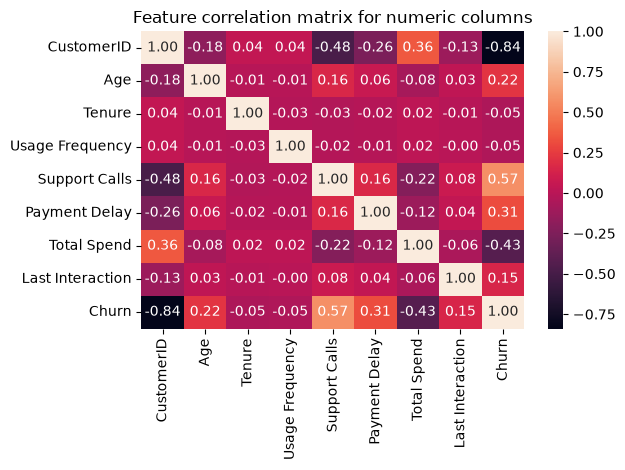

In [16]:
sns.heatmap(corr_matric, annot=True, fmt=".2f")
plt.title("Feature correlation matrix for numeric columns")
plt.tight_layout()
plt.show()

**From Heatmap:**
1 postive correlation exists for churn with age , support calls , payment delays and someone wiht last interaction.
2. Total spen is inversely related with churn.
3. Tenure doesnt seems to have much relation with churn

**Determine outliers in variables or features using box plots**

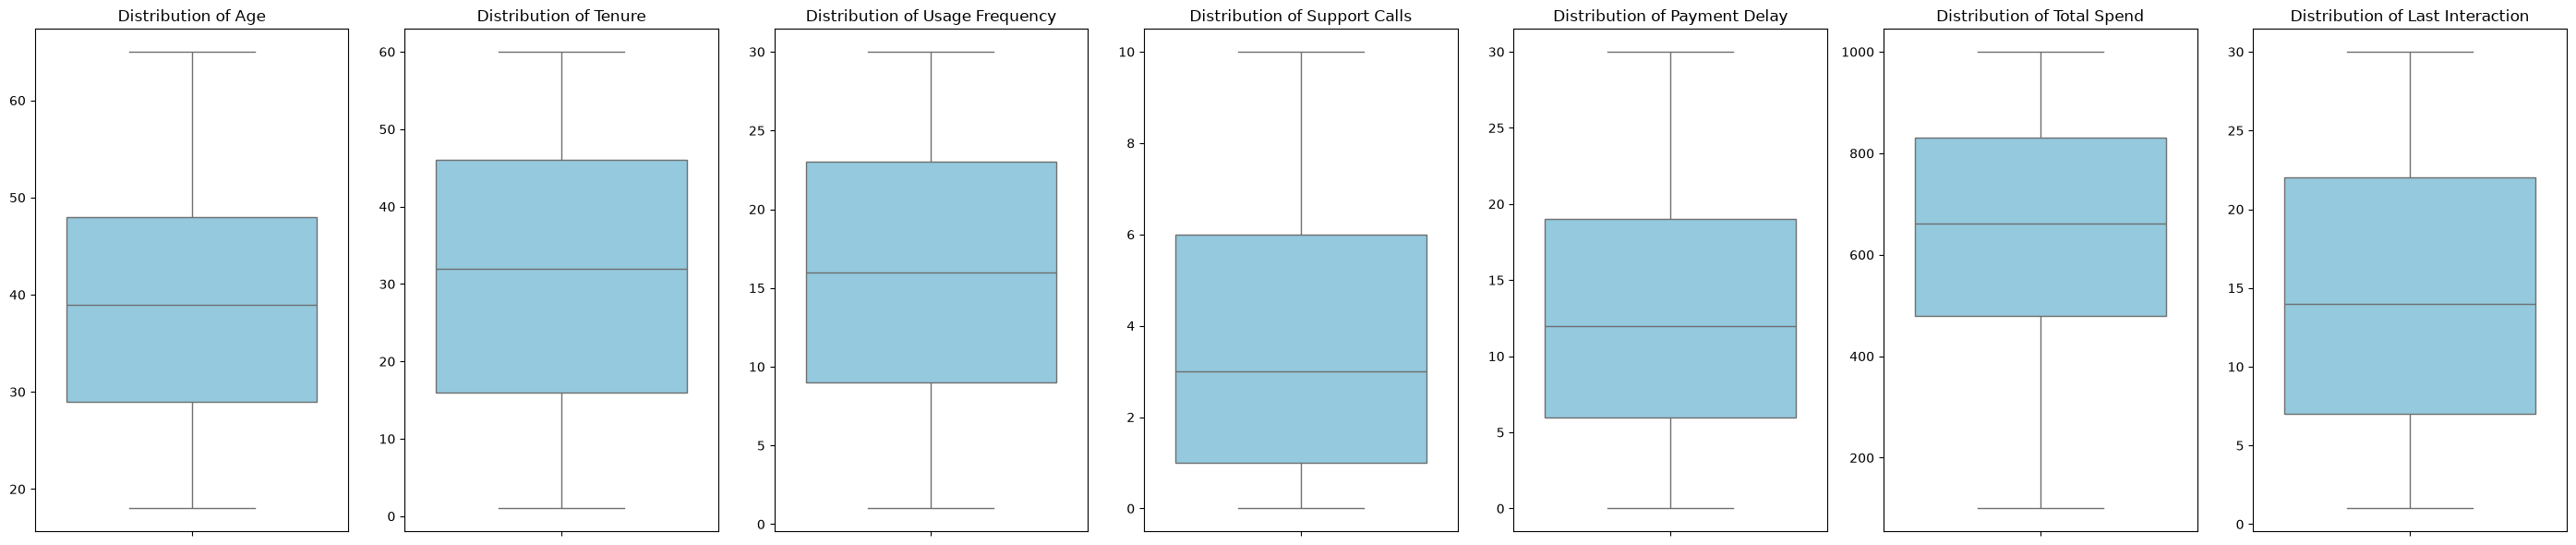

In [17]:
cols_to_plot = numeric_df.drop(columns=["CustomerID", "Churn"], errors="ignore")

# 2. Set up a grid of subplots dynamically based on the number of features
num_cols = len(cols_to_plot.columns)
fig, axes = plt.subplots(
    nrows=1, ncols=num_cols, figsize=(4 * num_cols, 6), sharey=False
)

# 3. Loop through columns and plot each on its own axis
for i, col in enumerate(cols_to_plot.columns):
    sns.boxplot(data=cols_to_plot, y=col, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}", fontsize=12)
    axes[i].set_ylabel("")  # Clears y-label so it doesn't crowd the title

# 4. Clean up the spacing and show the plot
plt.tight_layout()
plt.show()

**Feature Engineering**

In [18]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [19]:
df['f_Spend_Per_Usage'] = df['Total Spend'] / df ['Usage Frequency']
df['f_Spend_Per_Tenure'] = df['Total Spend'] / df ['Tenure']
df['f_SupportCalls_Tenure'] = round(df['Support Calls'] * 10 /df['Tenure'])
df['f_customer_friction_score'] = df['Support Calls'] * df ['Payment Delay']

In [20]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn,f_Spend_Per_Usage,f_Spend_Per_Tenure,f_SupportCalls_Tenure,f_customer_friction_score
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0,66.571429,23.897436,1.0,90.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0,557.000000,11.367347,2.0,80.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0,46.250000,13.214286,4.0,108.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0,18.857143,10.421053,2.0,49.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0,30.850000,19.281250,2.0,40.0


**Columns Encoding - Convert string column to numeric for classification**

In [21]:
onehot_categorical_cols = ["Subscription Type", "Contract Length"]

In [22]:
X_encoded = pd.get_dummies(df, columns=onehot_categorical_cols,drop_first=True)

In [23]:
gender_map = {"Female":0,"Male":1}
X_encoded["Gender"] = X_encoded["Gender"].map(gender_map)

In [24]:
X_encoded = X_encoded.astype(float)

In [25]:
X_encoded.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,f_Spend_Per_Usage,f_Spend_Per_Tenure,f_SupportCalls_Tenure,f_customer_friction_score,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,2.0,30.0,0.0,39.0,14.0,5.0,18.0,932.0,17.0,1.0,66.571429,23.897436,1.0,90.0,0.0,1.0,0.0,0.0
1,3.0,65.0,0.0,49.0,1.0,10.0,8.0,557.0,6.0,1.0,557.000000,11.367347,2.0,80.0,0.0,0.0,1.0,0.0
2,4.0,55.0,0.0,14.0,4.0,6.0,18.0,185.0,3.0,1.0,46.250000,13.214286,4.0,108.0,0.0,0.0,0.0,1.0
3,5.0,58.0,1.0,38.0,21.0,7.0,7.0,396.0,29.0,1.0,18.857143,10.421053,2.0,49.0,0.0,1.0,1.0,0.0
4,6.0,23.0,1.0,32.0,20.0,5.0,8.0,617.0,20.0,1.0,30.850000,19.281250,2.0,40.0,0.0,0.0,1.0,0.0


In [26]:
scaler = MinMaxScaler()

In [27]:
y = X_encoded[['Churn']]
X_encoded = X_encoded.drop(columns=['Churn','CustomerID'])

**PCA Dimensionality reduction**

In [28]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report,roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [29]:
X_copy = X_encoded.copy()

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X_copy, y, test_size=0.25, random_state=42)

In [31]:
pca_logistic_pipeline = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2)),
                                  ('logistic', LogisticRegression(
        #penalty='elasticnet', 
        solver='saga', 
        l1_ratio=0.5,                                  # Combines L1 and L2 regularization
        max_iter=1000, 
        random_state=42
    ))
])

pca_logistic_pipeline.fit(X_train, y_train)

/Users/hemil/miniconda3/envs/msdae/lib/python3.13/site-packages/sklearn/utils/validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Gender','Tenure',...,'Subscription Type_Standard', 'Contract Length_Monthly','Contract Length_Quarterly']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [32]:
y_pred = pca_logistic_pipeline.predict(X_test)
y_pred_proba = pca_logistic_pipeline.predict_proba(X_test)[:, 1]

In [33]:
print("\n--- Model Evaluation ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- Model Evaluation ---
ROC-AUC Score: 0.9315

Classification Report:
              precision    recall  f1-score   support

         0.0       0.82      0.85      0.84     47637
         1.0       0.88      0.85      0.87     62571

    accuracy                           0.85    110208
   macro avg       0.85      0.85      0.85    110208
weighted avg       0.86      0.85      0.85    110208



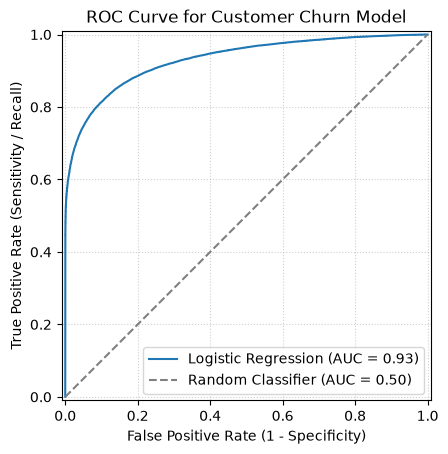

In [34]:
display = RocCurveDisplay.from_estimator(
    pca_logistic_pipeline, 
    X_test, 
    y_test, 
    name="Logistic Regression"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

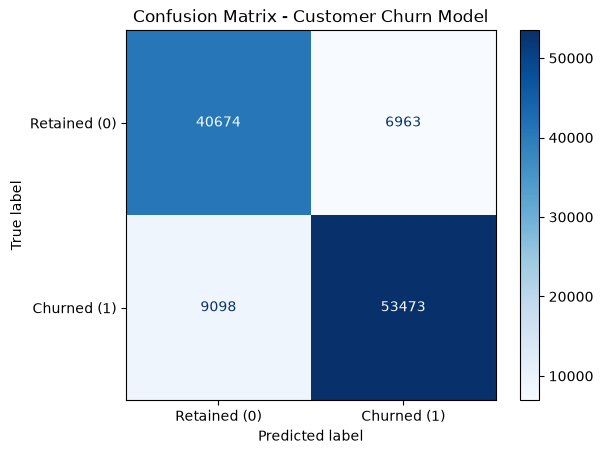

In [35]:
display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    values_format='d',
    display_labels=["Retained (0)", "Churned (1)"],
    cmap=plt.cm.Blues
)

# 2. Add titles and cosmetic details
plt.title("Confusion Matrix - Customer Churn Model")
plt.grid(False) # Turn off the default background grid lines for a cleaner look

# 3. Render the plot
plt.show()

In [36]:
scaler.fit(X_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](16,)","[65., 1.,60.,..., 1., 1., 1.]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](16,)","[18., 0., 1.,..., 0., 0., 0.]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](16,)","[47., 1.,59.,..., 1., 1., 1.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](16,)","['Age','Gender','Tenure',...,'Subscription Type_Standard', 'Contract Length_Monthly','Contract Length_Quarterly']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](16,)","[-0.38, 0. ,-0.02,..., 0. , 0. , 0. ]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,16
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,330624


In [37]:
X_train_scaled = scaler.transform(X_train)
X_train_scaled

array([[1.        , 0.        , 0.08474576, ..., 0.        , 1.        ,
        0.        ],
       [0.        , 1.        , 0.57627119, ..., 0.        , 0.        ,
        0.        ],
       [0.80851064, 1.        , 0.3559322 , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.40425532, 0.        , 0.13559322, ..., 0.        , 1.        ,
        0.        ],
       [0.31914894, 1.        , 0.44067797, ..., 0.        , 0.        ,
        0.        ],
       [0.70212766, 0.        , 0.93220339, ..., 1.        , 0.        ,
        0.        ]], shape=(330624, 16))

In [38]:
X_test_scaled = scaler.transform(X_test)

**Training/Prediction using Logistic Regression**

In [39]:
model = LogisticRegression(C=1.0, random_state=42, penalty='elasticnet', solver='saga', l1_ratio=0.5, class_weight='balanced',max_iter= 100000) #added class_weight to impreove accuracy

In [40]:
model.fit(X_train_scaled, y_train.values.ravel())

/Users/hemil/miniconda3/envs/msdae/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'elasticnet'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergenc

In [41]:
from sklearn.metrics import classification_report,roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [42]:
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Classification Report using training data:")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

Classification Report using training data:
              precision    recall  f1-score   support

         0.0       0.85      0.93      0.89     47637
         1.0       0.94      0.88      0.91     62571

    accuracy                           0.90    110208
   macro avg       0.90      0.90      0.90    110208
weighted avg       0.90      0.90      0.90    110208

ROC AUC Score: 0.9601


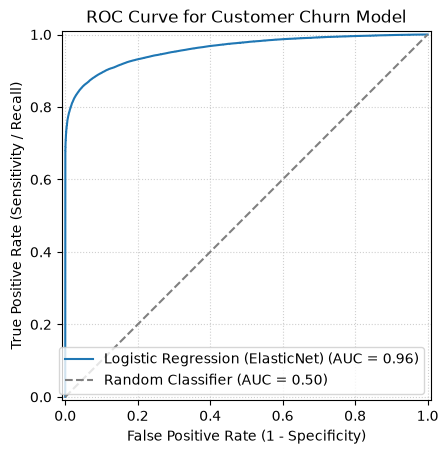

In [43]:
display = RocCurveDisplay.from_estimator(
    model, 
    X_test_scaled, 
    y_test, 
    name="Logistic Regression (ElasticNet)"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

In [44]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

print("Feature Importance (Coefficients):")
print(importance)

Feature Importance (Coefficients):
                       Feature  Coefficient
14     Contract Length_Monthly    10.983062
4                Support Calls     9.692462
6                  Total Spend    -5.658666
5                Payment Delay     4.762380
11   f_customer_friction_score    -4.661778
7             Last Interaction     1.777532
0                          Age     1.579432
10       f_SupportCalls_Tenure    -1.214760
1                       Gender    -1.155549
9           f_Spend_Per_Tenure     0.810979
2                       Tenure    -0.401071
8            f_Spend_Per_Usage     0.399034
3              Usage Frequency    -0.298637
12   Subscription Type_Premium    -0.132163
13  Subscription Type_Standard    -0.125976
15   Contract Length_Quarterly    -0.002230


**Using Test data to run through prediction using model generated out of training data**

In [45]:
test_df['f_Spend_Per_Usage'] = test_df['Total Spend'] / test_df ['Usage Frequency']
test_df['f_Spend_Per_Tenure'] = test_df['Total Spend'] / test_df ['Tenure']
test_df['f_SupportCalls_Tenure'] = round(test_df['Support Calls'] * 10 /test_df['Tenure'])
test_df['f_customer_friction_score'] = test_df['Support Calls'] * test_df ['Payment Delay']

In [46]:
y_test_actual = test_df['Churn']
X_test_raw = test_df.drop(columns=['Churn','CustomerID'])

X_test_raw_encoded = pd.get_dummies(X_test_raw, columns=onehot_categorical_cols,drop_first=True)
X_test_raw_encoded["Gender"] = X_test_raw_encoded["Gender"].map(gender_map)
X_test_raw_encoded = X_test_raw_encoded.astype(float)

X_test_raw_encoded = X_test_raw_encoded.reindex(columns=X_train.columns, fill_value=0)

**Prediction using PCA**

In [47]:
y_val_pred = pca_logistic_pipeline.predict(X_test_raw_encoded)
y_val_pred_proba = pca_logistic_pipeline.predict_proba(X_test_raw_encoded)[:, 1]


--- Generalization Evaluation (test_df) ---
Validation ROC-AUC Score: 0.8293

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.23      0.37     33881
           1       0.54      0.98      0.69     30493

    accuracy                           0.59     64374
   macro avg       0.74      0.61      0.53     64374
weighted avg       0.75      0.59      0.52     64374



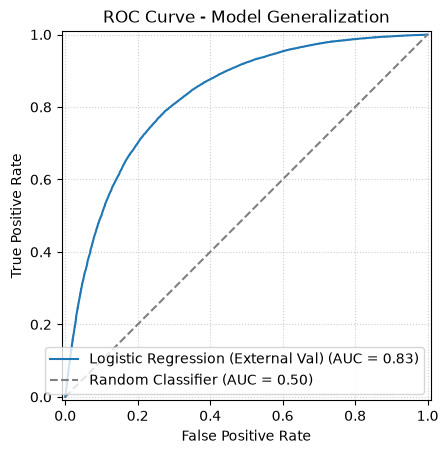

In [48]:
print("\n--- Generalization Evaluation (test_df) ---")
print(f"Validation ROC-AUC Score: {roc_auc_score(y_test_actual, y_val_pred_proba):.4f}")
print("\nValidation Classification Report:")
print(classification_report(y_test_actual, y_val_pred))

# 4. Optional: Plot the new ROC Curve to visually compare with your training curve
display = RocCurveDisplay.from_estimator(
    pca_logistic_pipeline, X_test_raw_encoded, y_test_actual, name="Logistic Regression (External Val)"
)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve - Model Generalization")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

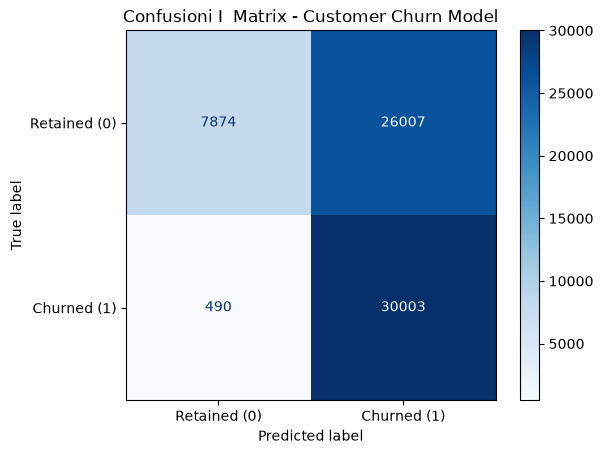

In [49]:
display = ConfusionMatrixDisplay.from_predictions(
    y_test_actual,
    y_val_pred,
    values_format='d',
    display_labels=["Retained (0)", "Churned (1)"],
    cmap=plt.cm.Blues
)

# 2. Add titles and cosmetic details
plt.title("Confusioni I  Matrix - Customer Churn Model")
plt.grid(False) # Turn off the default background grid lines for a cleaner look

# 3. Render the plot
plt.show()

In [50]:
X_test_raw_scaled = scaler.transform(X_test_raw_encoded)

In [51]:
y_test_preds = model.predict(X_test_raw_scaled)


In [52]:
y_test_preds

array([1., 1., 1., ..., 1., 1., 1.], shape=(64374,))

In [53]:
y_test_probs = model.predict_proba(X_test_raw_scaled)[:, 1]
print("Classification Report using test data:")
print(classification_report(y_test_actual, y_test_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test_actual, y_test_probs):.4f}")

Classification Report using test data:
              precision    recall  f1-score   support

           0       0.94      0.21      0.34     33881
           1       0.53      0.99      0.69     30493

    accuracy                           0.58     64374
   macro avg       0.73      0.60      0.52     64374
weighted avg       0.75      0.58      0.51     64374

ROC AUC Score: 0.6668


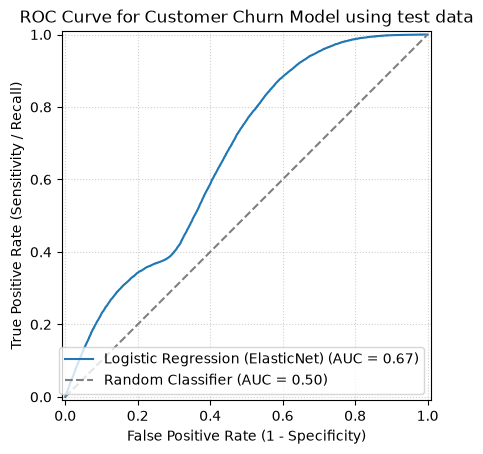

In [54]:
display = RocCurveDisplay.from_estimator(
    model, 
    X_test_raw_scaled, 
    y_test_actual, 
    name="Logistic Regression (ElasticNet)"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model using test data")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

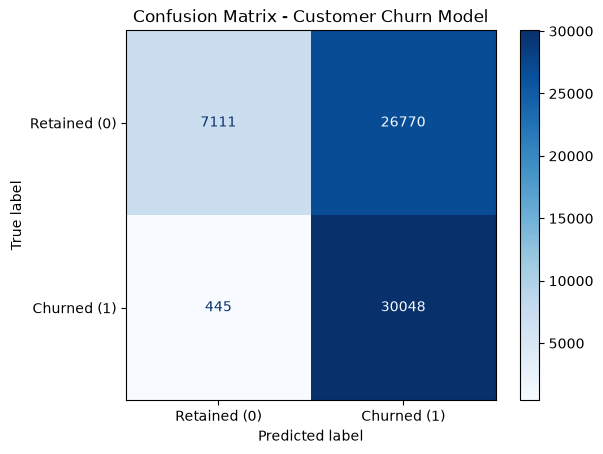

In [55]:
#1. Generate the confusion matrix from  test predictions
# This uses your true labels (y_test_actual) and the predicted classes (y_test_preds)
display = ConfusionMatrixDisplay.from_predictions(
    y_test_actual,
    y_test_preds,
    values_format='d',
    display_labels=["Retained (0)", "Churned (1)"],
    cmap=plt.cm.Blues
)

# 2. Add titles and cosmetic details
plt.title("Confusion Matrix - Customer Churn Model")
plt.grid(False) # Turn off the default background grid lines for a cleaner look

# 3. Render the plot
plt.show()

**Using Random Forest Classifier Model**

In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [57]:
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced',n_jobs=-1,max_depth=3,n_estimators=24)

In [58]:
X_train.columns

Index(['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Total Spend', 'Last Interaction', 'f_Spend_Per_Usage',
       'f_Spend_Per_Tenure', 'f_SupportCalls_Tenure',
       'f_customer_friction_score', 'Subscription Type_Premium',
       'Subscription Type_Standard', 'Contract Length_Monthly',
       'Contract Length_Quarterly'],
      dtype='str')

In [59]:
y_train.columns

Index(['Churn'], dtype='str')

In [60]:
rf_model.fit(X_train, y_train.values.ravel()) #Training RF model using non scaled values

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",24
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featur

In [62]:
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report using training data:")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

Classification Report using training data:
              precision    recall  f1-score   support

         0.0       0.89      0.99      0.94     47637
         1.0       0.99      0.91      0.95     62571

    accuracy                           0.95    110208
   macro avg       0.94      0.95      0.95    110208
weighted avg       0.95      0.95      0.95    110208

ROC AUC Score: 0.9917


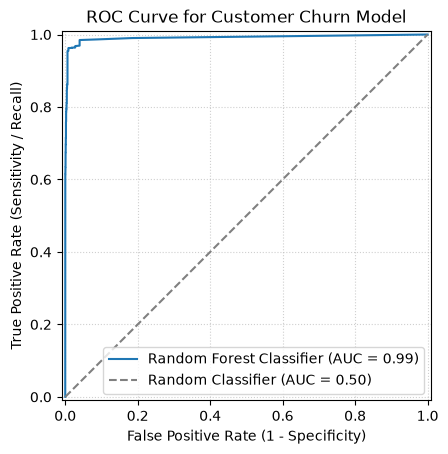

In [63]:
display = RocCurveDisplay.from_estimator(
    rf_model, 
    X_test, 
    y_test, 
    name="Random Forest Classifier"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

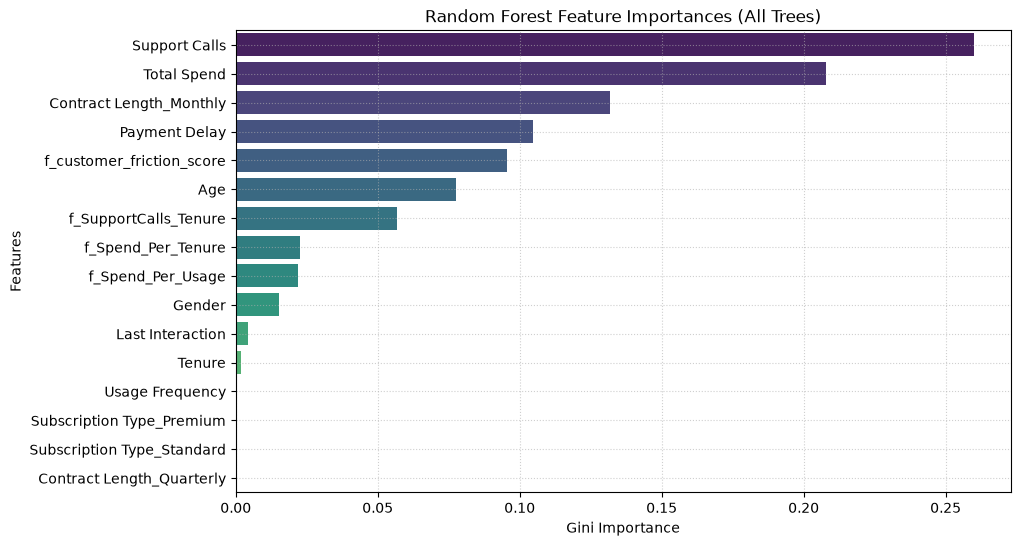

In [64]:
# Extract and sort feature importances
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index,palette="viridis")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importances (All Trees)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

**Predictions for test file data using Random forest model**

In [65]:
y_test_actual = test_df['Churn']
X_test_raw = test_df.drop(columns=['Churn','CustomerID'])

X_test_raw_encoded = pd.get_dummies(X_test_raw, columns=onehot_categorical_cols,drop_first=True)
X_test_raw_encoded["Gender"] = X_test_raw_encoded["Gender"].map(gender_map)
X_test_raw_encoded = X_test_raw_encoded.astype(float)

X_test_raw_encoded = X_test_raw_encoded.reindex(columns=X_train.columns, fill_value=0)

In [66]:
y_test_preds = rf_model.predict(X_test_raw_encoded)

In [67]:
y_test_probs = rf_model.predict_proba(X_test_raw_encoded)[:, 1]
print("Classification Report using test data:")
print(classification_report(y_test_actual, y_test_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test_actual, y_test_probs):.4f}")

Classification Report using test data:
              precision    recall  f1-score   support

           0       0.96      0.17      0.29     33881
           1       0.52      0.99      0.68     30493

    accuracy                           0.56     64374
   macro avg       0.74      0.58      0.49     64374
weighted avg       0.75      0.56      0.48     64374

ROC AUC Score: 0.7873


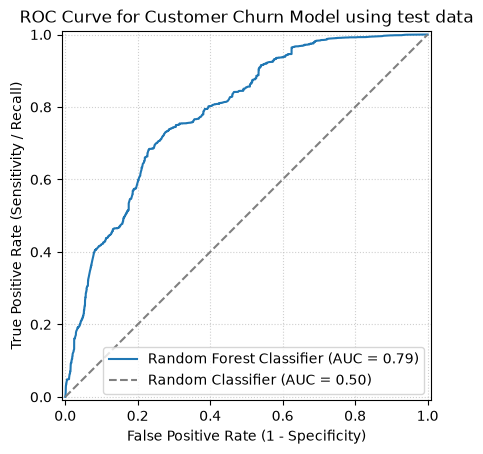

In [68]:
display = RocCurveDisplay.from_estimator(
    rf_model, 
    X_test_raw_encoded, 
    y_test_actual, 
    name="Random Forest Classifier"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model using test data")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

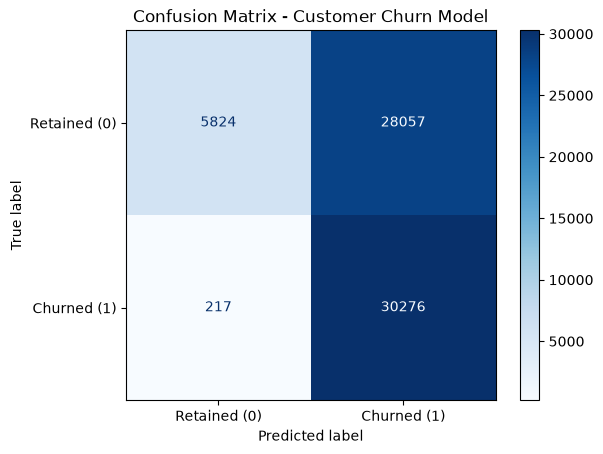

In [69]:
#1. Generate the confusion matrix from  test predictions
# This uses your true labels (y_test_actual) and the predicted classes (y_test_preds)
display = ConfusionMatrixDisplay.from_predictions(
    y_test_actual,
    y_test_preds,
    values_format='d',
    display_labels=["Retained (0)", "Churned (1)"],
    cmap=plt.cm.Blues
)

# 2. Add titles and cosmetic details
plt.title("Confusion Matrix - Customer Churn Model")
plt.grid(False) # Turn off the default background grid lines for a cleaner look

# 3. Render the plot
plt.show()

**Plot Decision Tree for analysis**

In [70]:
individual_tree = rf_model.estimators_[0]

In [71]:
from sklearn.tree import plot_tree

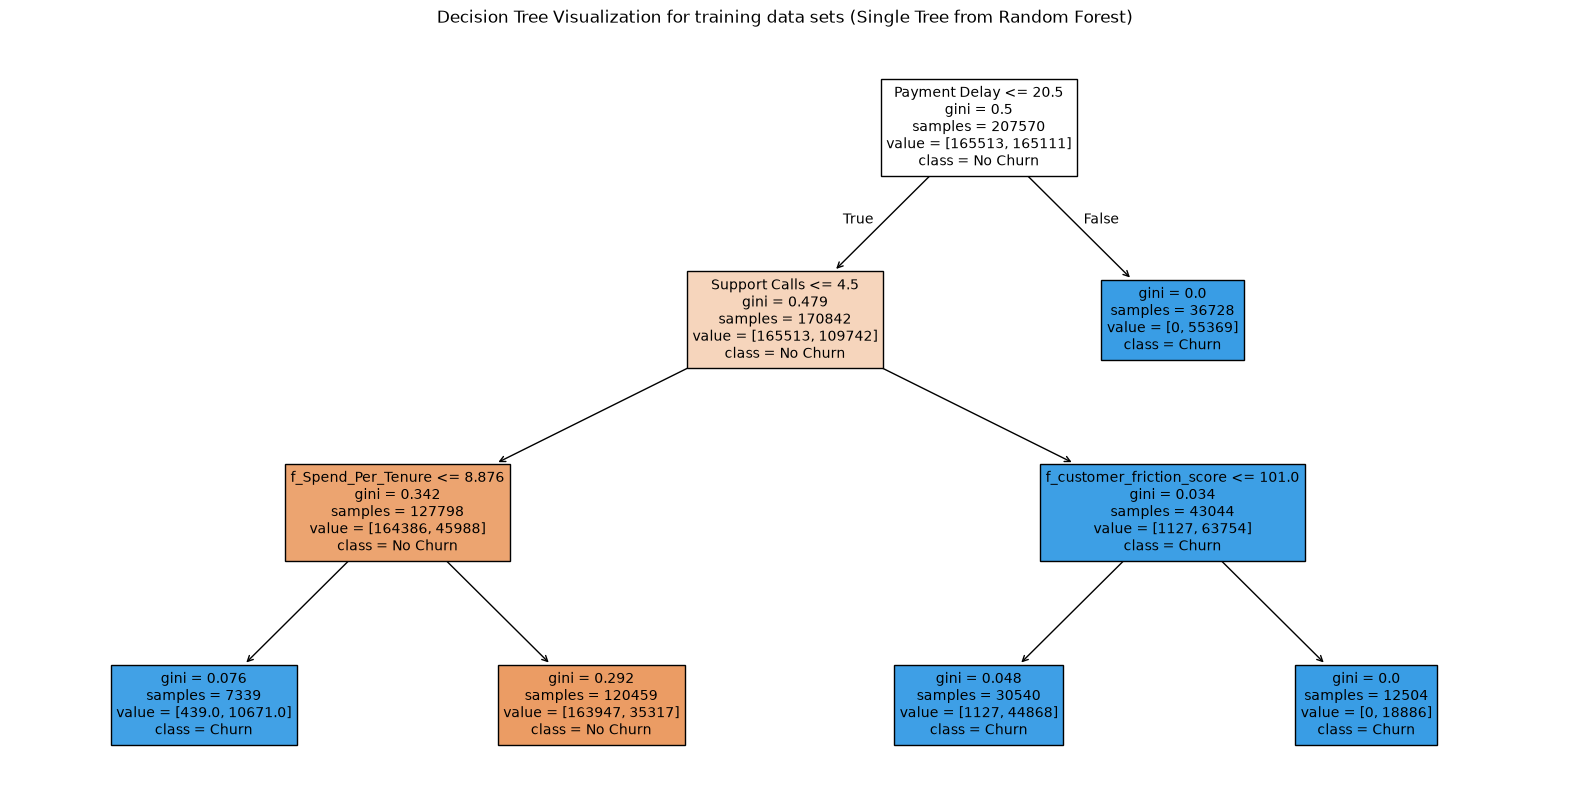

In [72]:
plt.figure(figsize=(20, 10))
plot_tree(
    individual_tree,
    feature_names=X_train.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    max_depth=3,  # Limit depth so the visualization remains readable
    fontsize=10
)
plt.title("Decision Tree Visualization for training data sets (Single Tree from Random Forest)")
plt.show()